In [147]:
import tensorflow as tf

from tensorflow import keras

from keras.datasets.cifar10 import load_data
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout, Flatten
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

import matplotlib.pyplot as plt

In [132]:
ds = load_data()
ds

((array([[[[ 59,  62,  63],
           [ 43,  46,  45],
           [ 50,  48,  43],
           ...,
           [158, 132, 108],
           [152, 125, 102],
           [148, 124, 103]],
  
          [[ 16,  20,  20],
           [  0,   0,   0],
           [ 18,   8,   0],
           ...,
           [123,  88,  55],
           [119,  83,  50],
           [122,  87,  57]],
  
          [[ 25,  24,  21],
           [ 16,   7,   0],
           [ 49,  27,   8],
           ...,
           [118,  84,  50],
           [120,  84,  50],
           [109,  73,  42]],
  
          ...,
  
          [[208, 170,  96],
           [201, 153,  34],
           [198, 161,  26],
           ...,
           [160, 133,  70],
           [ 56,  31,   7],
           [ 53,  34,  20]],
  
          [[180, 139,  96],
           [173, 123,  42],
           [186, 144,  30],
           ...,
           [184, 148,  94],
           [ 97,  62,  34],
           [ 83,  53,  34]],
  
          [[177, 144, 116],
           [16

In [133]:
(x_train, y_train), (x_test, y_test) = load_data()

In [134]:
len(x_train), len(x_test), len(y_train), len(y_test)

(50000, 10000, 50000, 10000)

In [135]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size = 0.2,
    stratify = y_train
)
len(x_train), len(y_train), len(x_test), len(y_test), len(x_val), len(y_val) 

(40000, 40000, 10000, 10000, 10000, 10000)

In [136]:
x_train[0]

array([[[174, 147, 137],
        [123, 102,  92],
        [ 96,  80,  71],
        ...,
        [ 24,  25,  25],
        [ 21,  22,  21],
        [ 21,  21,  21]],

       [[157, 143, 134],
        [ 75,  65,  58],
        [ 41,  35,  29],
        ...,
        [ 26,  24,  25],
        [ 20,  19,  19],
        [ 26,  25,  25]],

       [[ 74,  69,  63],
        [ 39,  38,  33],
        [ 32,  32,  30],
        ...,
        [ 27,  21,  24],
        [ 22,  18,  19],
        [ 26,  25,  25]],

       ...,

       [[155, 160, 179],
        [152, 157, 175],
        [148, 153, 171],
        ...,
        [174, 176, 191],
        [178, 180, 195],
        [181, 183, 198]],

       [[150, 155, 175],
        [154, 159, 178],
        [160, 165, 184],
        ...,
        [172, 174, 188],
        [174, 176, 191],
        [178, 180, 196]],

       [[149, 152, 171],
        [153, 156, 176],
        [153, 156, 175],
        ...,
        [169, 171, 185],
        [168, 170, 185],
        [172, 174, 189]]

In [137]:
x_train = preprocess_input(x_train.astype("float32"))
x_test = preprocess_input(x_test.astype("float32"))
x_val = preprocess_input(x_val.astype("float32"))

In [138]:
base_model = VGG16(
    weights="imagenet",
    include_top = False,
    input_shape = (32, 32, 3)
)

base_model.trainable = True

for layer in base_model.layers[:10]:
    layer.trainable = False

In [139]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 12,979,200 (49.51 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

In [140]:
model = Sequential([
    Input(shape=(32,32,3)),
    base_model,
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(.3),
    Dense(10, activation="softmax")
])
model.build()

In [141]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 13,046,154 (49.77 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

In [142]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience = 5,
    restore_best_weights = True
)

In [143]:
model.compile(
    optimizer=Adam(learning_rate= 0.000001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
    jit_compile = False
)
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 13,046,154 (49.77 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

In [146]:
history = model.fit(
    x_train,
    y_train,
    epochs=100,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping]
)

Epoch 1/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.6838 - loss: 0.9700 - val_accuracy: 0.7396 - val_loss: 0.8353
Epoch 2/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.6915 - loss: 0.9378 - val_accuracy: 0.7438 - val_loss: 0.8133
Epoch 3/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7040 - loss: 0.9034 - val_accuracy: 0.7481 - val_loss: 0.7955
Epoch 4/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7146 - loss: 0.8770 - val_accuracy: 0.7540 - val_loss: 0.7826
Epoch 5/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7224 - loss: 0.8538 - val_accuracy: 0.7574 - val_loss: 0.7655
Epoch 6/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7313 - loss: 0.8268 - val_accuracy: 0.7622 - val_loss: 0.7590
Epoch 7/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7387 - loss: 0.8091 - val_accuracy: 0.7617 - val_loss: 0.7475
Epoch 8/100
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7486 - loss: 0.7814 - 

In [152]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7961 - loss: 0.6616
Test Accuracy: 0.7961000204086304


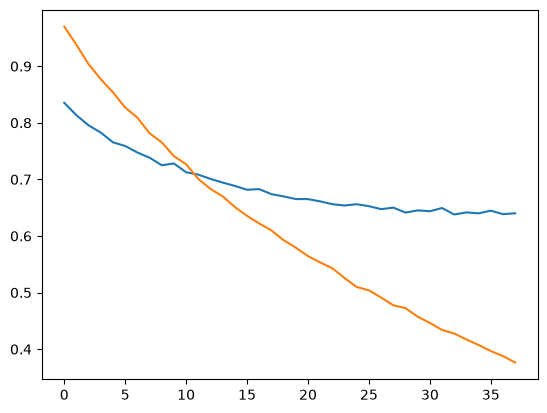

In [150]:
plt.plot(history.history['val_loss'])
plt.plot(history.history['loss'])

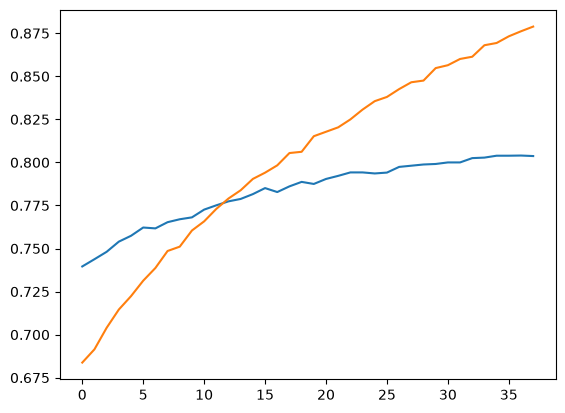

In [151]:
plt.plot(history.history['val_accuracy'])
plt.plot(history.history['accuracy'])